# 01 · The Artificial Neuron

**Learning objectives**
1. Compute a neuron's output by hand: weighted sum, bias, activation.
2. Implement the same computation with NumPy and check it against the hand calculation.
3. Explain why this one operation is repeated throughout a neural network.

## 1. Theoretical background

A biological neuron combines incoming signals and fires when the combined signal is strong enough. An artificial neuron keeps only the idea of *weighted combination followed by a threshold-like decision*.

## 2. Mathematical formulation

$$z = w_1 x_1 + w_2 x_2 + \cdots + w_n x_n + b = \mathbf{w}^\top \mathbf{x} + b, \qquad y = f(z)$$

| Symbol | Meaning |
|---|---|
| $x_i$ | input $i$ |
| $w_i$ | weight: how strongly input $i$ influences the output |
| $b$ | bias: shifts the decision point, independent of inputs |
| $z$ | pre-activation (weighted sum) |
| $f$ | activation function |
| $y$ | output |

Weights and bias are the **parameters**; training changes them. The activation $f$ is a **design choice**.

## 3. Step-by-step example (by hand)

$$\mathbf{x} = (1, 2, 3), \qquad \mathbf{w} = (0.5, -0.2, 0.1), \qquad b = 0.3$$

$$z = 0.5(1) + (-0.2)(2) + 0.1(3) + 0.3 = 0.5 - 0.4 + 0.3 + 0.3 = 0.7$$

The raw score is $0.7$. What it means depends on the activation.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

def neuron(x, w, b, f):
    """One neuron. x: (n,), w: (n,), b: scalar, f: activation. Returns a scalar."""
    z = np.dot(w, x) + b
    return f(z)


step = lambda z: 1.0 if z >= 0 else 0.0
sigmoid = lambda z: 1.0 / (1.0 + np.exp(-z))
relu = lambda z: max(0.0, z)

x = np.array([1.0, 2.0, 3.0])
w = np.array([0.5, -0.2, 0.1])
b = 0.3

print("z       =", np.dot(w, x) + b)
print("step    =", neuron(x, w, b, step))
print("sigmoid =", round(neuron(x, w, b, sigmoid), 4))
print("relu    =", neuron(x, w, b, relu))

z       = 0.7
step    = 1.0
sigmoid = 0.6682
relu    = 0.7


**Check.** The printed $z$ should be $0.7$, matching the hand calculation. The sigmoid output $\approx 0.6682$ is $\frac{1}{1+e^{-0.7}}$.

## 4. Visualization: a 2-input neuron as a surface

With two inputs and sigmoid activation, a neuron is a smooth surface over the plane. The contour $z = 0$ is where the output is $0.5$.

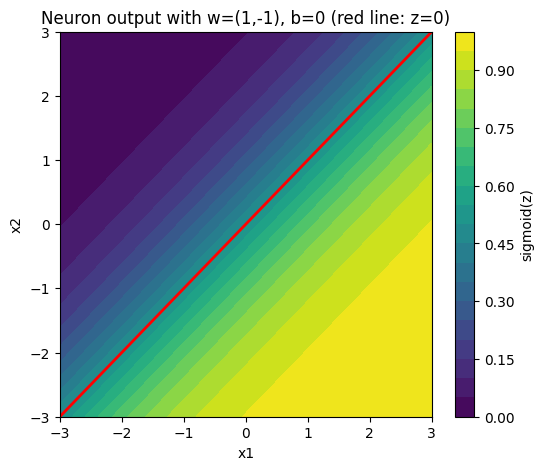

In [2]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

w2 = np.array([1.0, -1.0])
b2 = 0.0
g = np.linspace(-3, 3, 200)
X1, X2 = np.meshgrid(g, g)
Z = w2[0] * X1 + w2[1] * X2 + b2
Y = 1.0 / (1.0 + np.exp(-Z))

fig, ax = plt.subplots(figsize=(6, 5))
cf = ax.contourf(X1, X2, Y, levels=20, cmap="viridis")
ax.contour(X1, X2, Z, levels=[0], colors="red", linewidths=2)
fig.colorbar(cf, label="sigmoid(z)")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("Neuron output with w=(1,-1), b=0 (red line: z=0)")
plt.show()

## 5. Results and interpretation

- The weighted sum is a linear function of the inputs. Its zero set is a line (a hyperplane in higher dimensions).
- The activation turns that linear score into the output. Without a nonlinear activation, stacking neurons adds no expressive power (see the later modules).

## 6. Mathematical interpretation

The same formula $z = \mathbf{w}^\top \mathbf{x} + b$ is computed for every neuron in every layer. A dense layer of $m$ neurons is this operation applied with a weight matrix $W$ of shape $(n, m)$.

## 7. Conclusion

One neuron is a linear score followed by an activation. Everything else in a neural network is built by repeating and stacking this operation.

## 8. Exercises

1. Change $b$ to $-0.5$. What is $z$ for the same $\mathbf{x}$ and $\mathbf{w}$? Predict the step output first.
2. For $\mathbf{x} = (0, 0, 0)$, what is $z$ for any $\mathbf{w}$? Why does the bias matter here?
3. Compute $\mathrm{sigmoid}(0)$ by hand. Why is it the midpoint of the output range?